#### Extended Data Fig. S3: pattern-scaling differences with per-column FDR significance

Magenta hatching marks grid cells that are significant after Benjamini–Hochberg FDR correction (q ≤ 0.05) for the corresponding model, scenario, and column contrast.

In [26]:
import xarray as xr
import numpy as np
import os
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib import gridspec
import matplotlib.path as mpath
import matplotlib.ticker as mticker
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.util as cutil

scenarios = ["ssp119", "ssp126"]
LENS_name = ["MIROC", "MIROC-ES2L", "MPI-ESM-LR", "CanESM5"]

row_labels = [
    "MIROC6 (50)", "MIROC-ES2L (10)", "MPI-ESM1.2-LR (50)",
    "CanESM5 (50)"
]

base_dir = "/work/mh0033/m301036/Atlantic_heat_capacitor_Arctic/Atlantic_capacitor_on_Arctic/docs/data/Spatial_pattern/pattern_diff_4LEs/"
uncertainty_dir = "/work/mh0033/m301036/Atlantic_heat_capacitor_Arctic/Atlantic_capacitor_on_Arctic/scripts/SpatialPattern/data_35yr_segments/output/uncertainty_statistics_vs_HIST/"
fig_out = "/work/mh0033/m301036/Atlantic_heat_capacitor_Arctic/Atlantic_capacitor_on_Arctic/docs/figs/Extended_Fig3"
os.makedirs(fig_out, exist_ok=True)

# Each figure column uses its own member-wise contrast and FDR test.
FDR_CONTRAST_BY_TIMEFRAME = {
    "MT_vs_Present": "mid_minus_hist",
    "LT_vs_Present": "late_minus_hist",
    "LT_vs_MT": "late_minus_mid",
}

def load_fdr_mask(model, scenario, timeframe):
    contrast = FDR_CONTRAST_BY_TIMEFRAME[timeframe]
    path = f"{uncertainty_dir}{model}_{scenario}_{contrast}_LE_stats.nc"
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Missing FDR statistics for {model}, {scenario}, {timeframe}: {path}"
        )
    with xr.open_dataset(path) as ds:
        if "significant_fdr" not in ds:
            raise KeyError(f"'significant_fdr' is missing from {path}")
        mask = ds["significant_fdr"].load().astype(bool)
        mask.attrs.update(
            source_file=path,
            contrast=contrast,
            meaning="True where BH-FDR q <= alpha for the member-wise contrast",
        )
    return mask

ds_mid_response = {}
ds_long_response = {}
ds_long_vs_mid_response = {}
fdr_significant = {}

for model in LENS_name:
    print(f"Processing model: {model}")
    ds_mid_response[model] = xr.open_dataset(
        f"{base_dir}Beta_pattern_mid_vs_Present_differences_{model}.nc"
    )
    ds_long_response[model] = xr.open_dataset(
        f"{base_dir}Beta_pattern_long_vs_Present_differences_{model}.nc"
    )
    ds_long_vs_mid_response[model] = xr.open_dataset(
        f"{base_dir}Beta_pattern_long_vs_mid_differences_{model}.nc"
    )
    fdr_significant[model] = {
        scenario: {
            timeframe: load_fdr_mask(model, scenario, timeframe)
            for timeframe in FDR_CONTRAST_BY_TIMEFRAME
        }
        for scenario in scenarios
    }

Processing model: MIROC
Processing model: MIROC-ES2L
Processing model: MPI-ESM-LR
Processing model: CanESM5


#### Model-specific member notation

Each model uses different ensemble member notation and has different numbers of realizations:
- **CanESM5**: 50 members (25×i1p1f1 + 25×i1p2f1)
- **MIROC-ES2L**: 10 members (i1p1f2)
- **MPI-ESM-LR**: 50 members (i1p1f1)
- **MIROC6**: 50 members (i1p1f1)

In [27]:
# Define ensemble members for each model (models have different member notations)
members = {
    "CanESM5": [f"r{i}i1p1f1" for i in range(1, 26)] + [f"r{i}i1p2f1" for i in range(1, 26)],
    "MIROC-ES2L": [f"r{i}i1p1f2" for i in range(1, 11)],
    "MPI-ESM-LR": [f"r{i}i1p1f1" for i in range(1, 51)],
    "MIROC": [f"r{i}i1p1f1" for i in range(1, 51)]
}

print("Model-specific member definitions:")
for model, mem_list in members.items():
    print(f"  {model}: {len(mem_list)} members ({mem_list[0]} ... {mem_list[-1]})")

Model-specific member definitions:
  CanESM5: 50 members (r1i1p1f1 ... r25i1p2f1)
  MIROC-ES2L: 10 members (r1i1p1f2 ... r10i1p1f2)
  MPI-ESM-LR: 50 members (r1i1p1f1 ... r50i1p1f1)
  MIROC: 50 members (r1i1p1f1 ... r50i1p1f1)


In [28]:
ds_long_response

{'MIROC': <xarray.Dataset> Size: 26MB
 Dimensions:   (lat: 180, lon: 360, member: 50)
 Coordinates:
   * lat       (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 86.5 87.5 88.5 89.5
   * lon       (lon) float64 3kB 0.0 1.0 2.0 3.0 4.0 ... 356.0 357.0 358.0 359.0
   * member    (member) <U9 2kB 'r10i1p1f1' 'r11i1p1f1' ... 'r8i1p1f1' 'r9i1p1f1'
     scenario  <U6 24B ...
 Data variables:
     ssp119    (member, lat, lon) float32 13MB ...
     ssp126    (member, lat, lon) float32 13MB ...,
 'MIROC-ES2L': <xarray.Dataset> Size: 5MB
 Dimensions:   (lat: 180, lon: 360, member: 10)
 Coordinates:
   * lat       (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 86.5 87.5 88.5 89.5
   * lon       (lon) float64 3kB 0.0 1.0 2.0 3.0 4.0 ... 356.0 357.0 358.0 359.0
   * member    (member) <U9 360B 'r10i1p1f2' 'r1i1p1f2' ... 'r8i1p1f2' 'r9i1p1f2'
     scenario  <U6 24B ...
 Data variables:
     ssp119    (member, lat, lon) float32 3MB ...
     ssp126    (member, lat, lon) float32 3MB ...,
 'MPI-ESM-LR': <

In [29]:
# Inspect one set of per-column FDR masks.
fdr_significant["MIROC"]["ssp119"]

{'MT_vs_Present': <xarray.DataArray 'significant_fdr' (lat: 180, lon: 360)> Size: 65kB
 array([[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [ True,  True,  True, ...,  True,  True,  True],
        [ True,  True,  True, ...,  True,  True,  True],
        [ True,  True,  True, ...,  True,  True,  True]], shape=(180, 360))
 Coordinates:
   * lat      (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 86.5 87.5 88.5 89.5
   * lon      (lon) float64 3kB 0.0 1.0 2.0 3.0 4.0 ... 356.0 357.0 358.0 359.0
 Attributes:
     flag_values:    [0 1]
     flag_meanings:  false true
     source_file:    /work/mh0033/m301036/Atlantic_heat_capacitor_Arctic/Atlan...
     contrast:       mid_minus_hist
     meaning:        True where BH-FDR q <= alpha for the member-wise contrast,
 'LT_vs_Present': <xarray.DataArray 'significant_fdr' (lat: 180, lon: 360)> Size: 65kB
 array([

In [30]:
colors_255 = [
    (32, 54, 79),
    (49, 100, 108),
    (78, 146, 128),
    (150, 184, 155),
    (220, 223, 210),
    (236, 217, 207),
    (212, 156, 135),
    (184, 98, 101),
    (139, 52, 94),
    (80, 24, 78),
]
colors = [(r/255, g/255, b/255) for r, g, b in colors_255]
aru_cmap_div = LinearSegmentedColormap.from_list("aru_pastel_div", colors, N=256)

In [31]:
def circular_boundary(ax, radius=0.5):
    theta = np.linspace(0, 2 * np.pi, 200)
    center = [0.5, 0.5]
    verts = np.vstack([np.sin(theta), np.cos(theta)]).T * radius + center
    return mpath.Path(verts)

def to_0360(da):
    if "lon" in da.coords and bool((da.lon < 0).any()):
        da = da.assign_coords(lon=(da.lon % 360)).sortby("lon")
    return da

def prepare_lsm_on_grid(ref2d):
    lsm_path = "/work/mh0033/m301036/Data_storage/Data/GR15_lsm_regrid_1deg.nc"
    with xr.open_dataset(lsm_path) as ds:
        lsm = ds["var1"].load()

    rename_dict = {}
    if "latitude" in lsm.dims:
        rename_dict["latitude"] = "lat"
    if "longitude" in lsm.dims:
        rename_dict["longitude"] = "lon"
    if rename_dict:
        lsm = lsm.rename(rename_dict)

    if ref2d.lon.min() >= 0:
        lsm = to_0360(lsm)

    lsm = lsm.interp_like(ref2d)
    return (lsm == 0).squeeze(drop=True)  # True over ocean, False over land

def _draw_hatch(
    ax, lon2d, lat2d, min_lat, hatch_mask, ocean_mask,
    hatch_pattern, hatch_color, zorder
):
    hm = np.asarray(hatch_mask)
    if isinstance(hm, np.ma.MaskedArray):
        hm = hm.filled(False)
    hm = np.squeeze(hm).astype(bool)

    if hm.shape != lat2d.shape:
        if hm.T.shape == lat2d.shape:
            hm = hm.T
        else:
            raise ValueError(
                f"hatch mask shape {hm.shape} does not match map shape {lat2d.shape}"
            )

    if ocean_mask is None:
        om = np.ones_like(hm, dtype=bool)
    else:
        om = np.asarray(ocean_mask)
        if isinstance(om, np.ma.MaskedArray):
            om = om.filled(False)
        om = np.squeeze(om).astype(bool)
        if om.shape != lat2d.shape:
            if om.T.shape == lat2d.shape:
                om = om.T
            else:
                raise ValueError(
                    f"ocean mask shape {om.shape} does not match map shape {lat2d.shape}"
                )

    hatch_field = np.where((lat2d >= min_lat) & hm & om, 1.0, np.nan)
    if not np.isfinite(hatch_field).any():
        return

    n0 = len(ax.collections)
    ax.contourf(
        lon2d, lat2d, hatch_field,
        levels=[0.5, 1.5], hatches=[hatch_pattern], colors="none",
        transform=ccrs.PlateCarree(), zorder=zorder
    )
    for collection in ax.collections[n0:]:
        collection.set_facecolor("none")
        collection.set_edgecolor(hatch_color)
        collection.set_linewidth(0.0)

def plot_data_polar(
    data, lats, lons, ax, levels, cmap, extend="both", title="",
    show_xticks=True, show_yticks=True, label_longitude=False,
    min_lat=66.5, hatch_mask=None, hatch_pattern="///",
    hatch_color="azure", ocean_mask=None
):
    lon2d, lat2d = np.meshgrid(lons, lats)
    masked_data = np.where(lat2d >= min_lat, data, np.nan)

    cf = ax.contourf(
        lon2d, lat2d, masked_data,
        levels=levels, cmap=cmap, extend=extend,
        transform=ccrs.PlateCarree(), zorder=1
    )

    ax.set_extent([-180, 180, min_lat, 90], crs=ccrs.PlateCarree())
    ax.coastlines(linewidth=0.45, zorder=4)
    ax.set_boundary(circular_boundary(ax), transform=ax.transAxes)

    gl = ax.gridlines(
        crs=ccrs.PlateCarree(), draw_labels=False,
        linewidth=0.35, linestyle="--", color="gray", alpha=0.5
    )
    if show_xticks:
        gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
    if show_yticks:
        gl.ylocator = mticker.FixedLocator(np.arange(min_lat, 91, 15))

    if label_longitude:
        for lon in np.arange(0, 360, 60):
            ax.text(
                lon, min_lat + 2.0, f"{lon}°",
                transform=ccrs.PlateCarree(),
                ha="center", va="center", fontsize=8, color=""
            )

    if hatch_mask is not None:
        _draw_hatch(
            ax, lon2d, lat2d, min_lat, hatch_mask, ocean_mask,
            hatch_pattern, hatch_color, zorder=3
        )

    ax.set_title(title, fontsize=10, pad=3)
    return cf

In [32]:
def get_beta_and_fdr_mask(model, scenario, timeframe, ocean_mask_2d):
    """Return the plotted beta field and its matching per-column FDR mask."""
    if timeframe == "MT_vs_Present":
        beta_container = ds_mid_response
    elif timeframe == "LT_vs_Present":
        beta_container = ds_long_response
    elif timeframe == "LT_vs_MT":
        beta_container = ds_long_vs_mid_response
    else:
        raise ValueError(f"Unknown time frame: {timeframe}")

    if model not in beta_container:
        raise KeyError(
            f"{model} missing for {timeframe}. Available models: {list(beta_container)}"
        )
    if scenario not in beta_container[model].data_vars:
        raise KeyError(
            f"{scenario} missing for model={model}, timeframe={timeframe}. "
            f"Available variables: {list(beta_container[model].data_vars)}"
        )

    beta = beta_container[model][scenario]
    if "member" in beta.dims:
        beta = beta.mean("member", skipna=True)
    if "model" in beta.dims:
        if "model" in beta.coords and model in beta.model.values:
            beta = beta.sel(model=model)
        else:
            index = LENS_name.index(model) if beta.sizes["model"] == len(LENS_name) else 0
            beta = beta.isel(model=index, drop=True)

    fdr_mask = fdr_significant[model][scenario][timeframe]
    beta = to_0360(beta).squeeze(drop=True).transpose("lat", "lon")
    fdr_mask = to_0360(fdr_mask).squeeze(drop=True).transpose("lat", "lon")
    ocean_mask_2d = to_0360(ocean_mask_2d).squeeze(drop=True).transpose("lat", "lon")

    try:
        beta, fdr_mask, ocean_mask_2d = xr.align(
            beta, fdr_mask, ocean_mask_2d, join="exact"
        )
    except ValueError as exc:
        raise ValueError(
            f"Grid mismatch for {model}, {scenario}, {timeframe}; "
            "the plotted field and FDR mask must use identical lat/lon coordinates."
        ) from exc

    fdr_mask = fdr_mask.fillna(False).astype(bool)
    fdr_mask = fdr_mask.where(ocean_mask_2d, False)
    print(
        f"Loaded {model} {scenario} {timeframe}: beta={beta.shape}, "
        f"FDR-significant ocean cells={int(fdr_mask.sum())}"
    )
    return beta, fdr_mask

In [36]:
def make_4le_figure_for_scenario(
    scenario="ssp119",
    hatch_color="white",      # dark gray instead of magenta
    hatch_pattern="//",      # less dense than ///
    hatch_linewidth=0.35,    # thinner hatch lines
):
    """
    Plot member-paired changes in warming pattern scaling for four LEs.

    Columns:
      1. CO2 increase  - Historical
      2. CO2 decrease  - Historical
      3. CO2 decrease  - CO2 increase

    Hatching:
      Grid cells where the member-wise paired contrast is significant
      after Benjamini-Hochberg FDR correction (q <= 0.05).
    """

    # -------------------------------------------------------------
    # Hatch appearance
    # -------------------------------------------------------------
    # This controls hatch-line thickness globally for this figure.
    plt.rcParams["hatch.linewidth"] = hatch_linewidth

    tf_order = [
        "MT_vs_Present",
        "LT_vs_Present",
        "LT_vs_MT",
    ]

    # Shorter, cleaner titles
    col_titles = [
        r"CO$_2$$\uparrow$ $-$ Hist.",
        r"CO$_2$$\downarrow$ $-$ Hist.",
        r"CO$_2$$\downarrow$ $-$ CO$_2$$\uparrow$",
    ]

    # -------------------------------------------------------------
    # Reference grid / mask
    # -------------------------------------------------------------
    ref = ds_mid_response[LENS_name[0]][scenario]

    if "member" in ref.dims:
        ref = ref.isel(member=0, drop=True)

    ref = (
        to_0360(ref)
        .squeeze(drop=True)
        .transpose("lat", "lon")
    )

    ocean_mask_2d = (
        prepare_lsm_on_grid(ref)
        .transpose("lat", "lon")
    )

    # -------------------------------------------------------------
    # Colour levels
    # -------------------------------------------------------------
    levels = np.arange(-5.0, 5.5, 0.5)

    # -------------------------------------------------------------
    # Figure layout
    # -------------------------------------------------------------
    fig = plt.figure(figsize=(15, 20))

    gs = gridspec.GridSpec(
        len(LENS_name),
        3,
        figure=fig,
        left=0.10,
        right=0.90,
        top=0.97,
        bottom=0.20,
        wspace=0.06,
        hspace=0.08,
    )

    axs = np.empty(
        (len(LENS_name), 3),
        dtype=object,
    )

    for i in range(len(LENS_name)):
        for j in range(3):
            axs[i, j] = fig.add_subplot(
                gs[i, j],
                projection=ccrs.NorthPolarStereo(),
            )

    last_cf = None

    # -------------------------------------------------------------
    # Main plotting loop
    # -------------------------------------------------------------
    for i, model in enumerate(LENS_name):

        for j, timeframe in enumerate(tf_order):

            ax = axs[i, j]

            beta, fdr_mask = get_beta_and_fdr_mask(
                model,
                scenario,
                timeframe,
                ocean_mask_2d,
            )

            # -----------------------------------------------------
            # Add cyclic longitude point
            # -----------------------------------------------------
            data_cyclic, lon_cyclic = cutil.add_cyclic_point(
                beta.values,
                coord=beta.lon.values,
                axis=-1,
            )

            fdr_cyclic, _ = cutil.add_cyclic_point(
                fdr_mask.values.astype(bool),
                coord=fdr_mask.lon.values,
                axis=-1,
            )

            ocean_cyclic, _ = cutil.add_cyclic_point(
                ocean_mask_2d.values.astype(bool),
                coord=ocean_mask_2d.lon.values,
                axis=-1,
            )

            # -----------------------------------------------------
            # Main field + significance hatching
            # -----------------------------------------------------
            last_cf = plot_data_polar(
                data=data_cyclic,
                lats=beta.lat.values,
                lons=lon_cyclic,
                ax=ax,
                levels=levels,
                cmap=aru_cmap_div,
                extend="both",
                min_lat=66.5,

                # FDR significance overlay
                hatch_mask=fdr_cyclic,
                hatch_pattern=hatch_pattern,
                hatch_color=hatch_color,

                ocean_mask=ocean_cyclic,
            )

            # -----------------------------------------------------
            # Land
            # -----------------------------------------------------
            ax.add_feature(
                cfeature.LAND,
                facecolor="lightgrey",
                edgecolor="none",
                zorder=3.5,
            )

            # -----------------------------------------------------
            # Column titles
            # -----------------------------------------------------
            if i == 0:
                ax.set_title(
                    col_titles[j],
                    fontsize=18,
                    pad=10,
                )

            # -----------------------------------------------------
            # Row labels
            # -----------------------------------------------------
            if j == 0:
                ax.text(
                    -0.18,
                    0.5,
                    row_labels[i],
                    transform=ax.transAxes,
                    rotation=90,
                    fontsize=16,
                    # fontweight="bold",
                    ha="center",
                    va="center",
                )

    # -------------------------------------------------------------
    # Panel labels a-d
    # -------------------------------------------------------------
    for i in range(len(LENS_name)):
        axs[i, 0].text(
            -0.05,
            1.02,
            chr(97 + i),
            transform=axs[i, 0].transAxes,
            fontsize=24,
            fontweight="bold",
            va="center",
            ha="center",
        )

    # -------------------------------------------------------------
    # Colorbar
    # -------------------------------------------------------------
    cbar_ax = fig.add_axes(
        [0.20, 0.165, 0.60, 0.012]
    )

    cbar = fig.colorbar(
        last_cf,
        cax=cbar_ax,
        orientation="horizontal",
        extend="both",
    )

    cbar.set_ticks(levels[::2])

    cbar.ax.tick_params(
        labelsize=12,
        length=7,
        width=1.4,
        color="0.2",
    )

    cbar.ax.set_xticklabels(
        [f"{int(x)}" for x in levels[::2]],
        fontsize=14,
    )

    cbar.outline.set_linewidth(1.2)
    cbar.ax.minorticks_off()

    cbar.set_label(
        r"Warming pattern scaling difference (°C/°C)",
        fontsize=18,
    )
      # -------------------------------------------------------------
    # Optional significance explanation
    # -------------------------------------------------------------
    fig.text(
        0.50,
        0.125,
        r"Hatching: member-wise paired contrast, "
        r"BH-FDR $q \leq 0.05$",
        ha="center",
        va="center",
        fontsize=16,
        color="0.25",
    )

    # -------------------------------------------------------------
    # Save
    # -------------------------------------------------------------
    stem = (
        f"{fig_out}/"
        f"Fig_S3_4LE_{scenario}_pattern_scaling_with_FDRSignificance"
    )

    plt.savefig(
        f"{stem}.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.savefig(
        f"{stem}.pdf",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

In [37]:
# def make_4le_figure_for_scenario(scenario="ssp119", hatch_color="magenta"):
#     tf_order = ["MT_vs_Present", "LT_vs_Present", "LT_vs_MT"]
#     col_titles = ["$\\mathbf{CO_{2}}$ increase",
#     "$\\mathbf{CO_{2}}$ decrease", "$\\mathbf{CO_{2}}$ decrease - $\\mathbf{CO_{2}}$ increase"]

#     ref = ds_mid_response[LENS_name[0]][scenario]
#     if "member" in ref.dims:
#         ref = ref.isel(member=0, drop=True)
#     ref = to_0360(ref).squeeze(drop=True).transpose("lat", "lon")
#     ocean_mask_2d = prepare_lsm_on_grid(ref).transpose("lat", "lon")

#     levels = np.arange(-5.0, 5.5, 0.5)
#     fig = plt.figure(figsize=(15, 20))
#     gs = gridspec.GridSpec(
#         len(LENS_name), 3, figure=fig,
#         left=0.10, right=0.90, top=0.97, bottom=0.20,
#         wspace=0.06, hspace=0.08
#     )

#     axs = np.empty((len(LENS_name), 3), dtype=object)
#     for i in range(len(LENS_name)):
#         for j in range(3):
#             axs[i, j] = fig.add_subplot(
#                 gs[i, j], projection=ccrs.NorthPolarStereo()
#             )

#     last_cf = None
#     for i, model in enumerate(LENS_name):
#         for j, timeframe in enumerate(tf_order):
#             ax = axs[i, j]
#             beta, fdr_mask = get_beta_and_fdr_mask(
#                 model, scenario, timeframe, ocean_mask_2d
#             )

#             data_cyclic, lon_cyclic = cutil.add_cyclic_point(
#                 beta.values, coord=beta.lon.values, axis=-1
#             )
#             fdr_cyclic, _ = cutil.add_cyclic_point(
#                 fdr_mask.values.astype(bool), coord=fdr_mask.lon.values, axis=-1
#             )
#             ocean_cyclic, _ = cutil.add_cyclic_point(
#                 ocean_mask_2d.values.astype(bool),
#                 coord=ocean_mask_2d.lon.values, axis=-1
#             )

#             last_cf = plot_data_polar(
#                 data=data_cyclic,
#                 lats=beta.lat.values,
#                 lons=lon_cyclic,
#                 ax=ax,
#                 levels=levels,
#                 cmap=aru_cmap_div,
#                 extend="both",
#                 min_lat=66.5,
#                 hatch_mask=fdr_cyclic,
#                 hatch_pattern="///",
#                 hatch_color=hatch_color,
#                 ocean_mask=ocean_cyclic,
#             )

#             ax.add_feature(
#                 cfeature.LAND, facecolor="lightgrey", edgecolor="none", zorder=3.5
#             )
#             if i == 0:
#                 ax.set_title(col_titles[j], fontsize=22, pad=10)
#             if j == 0:
#                 ax.text(
#                     -0.18, 0.5, row_labels[i], transform=ax.transAxes,
#                     rotation=90, fontsize=26, fontweight="bold",
#                     ha="center", va="center"
#                 )

#     for i in range(len(LENS_name)):
#         axs[i, 0].text(
#             -0.05, 1.02, chr(97 + i), transform=axs[i, 0].transAxes,
#             fontsize=18, fontweight="bold", va="center", ha="center"
#         )

#     # fig.text(
#     #     0.50, 0.165,
#     #     "Magenta hatching: significant member-wise contrast "
#     #     "(Benjamini–Hochberg FDR q ≤ 0.05; cells ≥66.5°N)",
#     #     ha="center", va="center", fontsize=11, color="magenta"
#     # )
#     cbar_ax = fig.add_axes([0.20, 0.15, 0.60, 0.012])
#     cbar = fig.colorbar(last_cf, cax=cbar_ax, orientation="horizontal", extend="both")
#     # cbar.set_ticks(levels[::2])
#     # cbar.ax.tick_params(labelsize=18)
#     cbar.set_ticks(levels[::2])
#     cbar.ax.tick_params(labelsize=18, length=7, width=1.4, color='0.2')
#     cbar.ax.set_xticklabels([f"{int(x)}" for x in levels[::2]], fontsize=18)
#     cbar.outline.set_linewidth(1.2)
#     cbar.ax.minorticks_off()
#     cbar.set_label(r"$\Delta$ Warming pattern scaling (°C/°C)", fontsize=20)

#     stem = f"{fig_out}/Fig_S3_4LE_{scenario}_pattern_scaling_with_FDRSignificance"
#     plt.savefig(f"{stem}.png", dpi=300, bbox_inches="tight")
#     plt.savefig(f"{stem}.pdf", dpi=300, bbox_inches="tight")
#     plt.show()

Loaded MIROC ssp119 MT_vs_Present: beta=(180, 360), FDR-significant ocean cells=4778
Loaded MIROC ssp119 LT_vs_Present: beta=(180, 360), FDR-significant ocean cells=1208
Loaded MIROC ssp119 LT_vs_MT: beta=(180, 360), FDR-significant ocean cells=4978
Loaded MIROC-ES2L ssp119 MT_vs_Present: beta=(180, 360), FDR-significant ocean cells=2804
Loaded MIROC-ES2L ssp119 LT_vs_Present: beta=(180, 360), FDR-significant ocean cells=0
Loaded MIROC-ES2L ssp119 LT_vs_MT: beta=(180, 360), FDR-significant ocean cells=268
Loaded MPI-ESM-LR ssp119 MT_vs_Present: beta=(180, 360), FDR-significant ocean cells=698
Loaded MPI-ESM-LR ssp119 LT_vs_Present: beta=(180, 360), FDR-significant ocean cells=3802
Loaded MPI-ESM-LR ssp119 LT_vs_MT: beta=(180, 360), FDR-significant ocean cells=4517
Loaded CanESM5 ssp119 MT_vs_Present: beta=(180, 360), FDR-significant ocean cells=5163
Loaded CanESM5 ssp119 LT_vs_Present: beta=(180, 360), FDR-significant ocean cells=2015
Loaded CanESM5 ssp119 LT_vs_MT: beta=(180, 360), FD

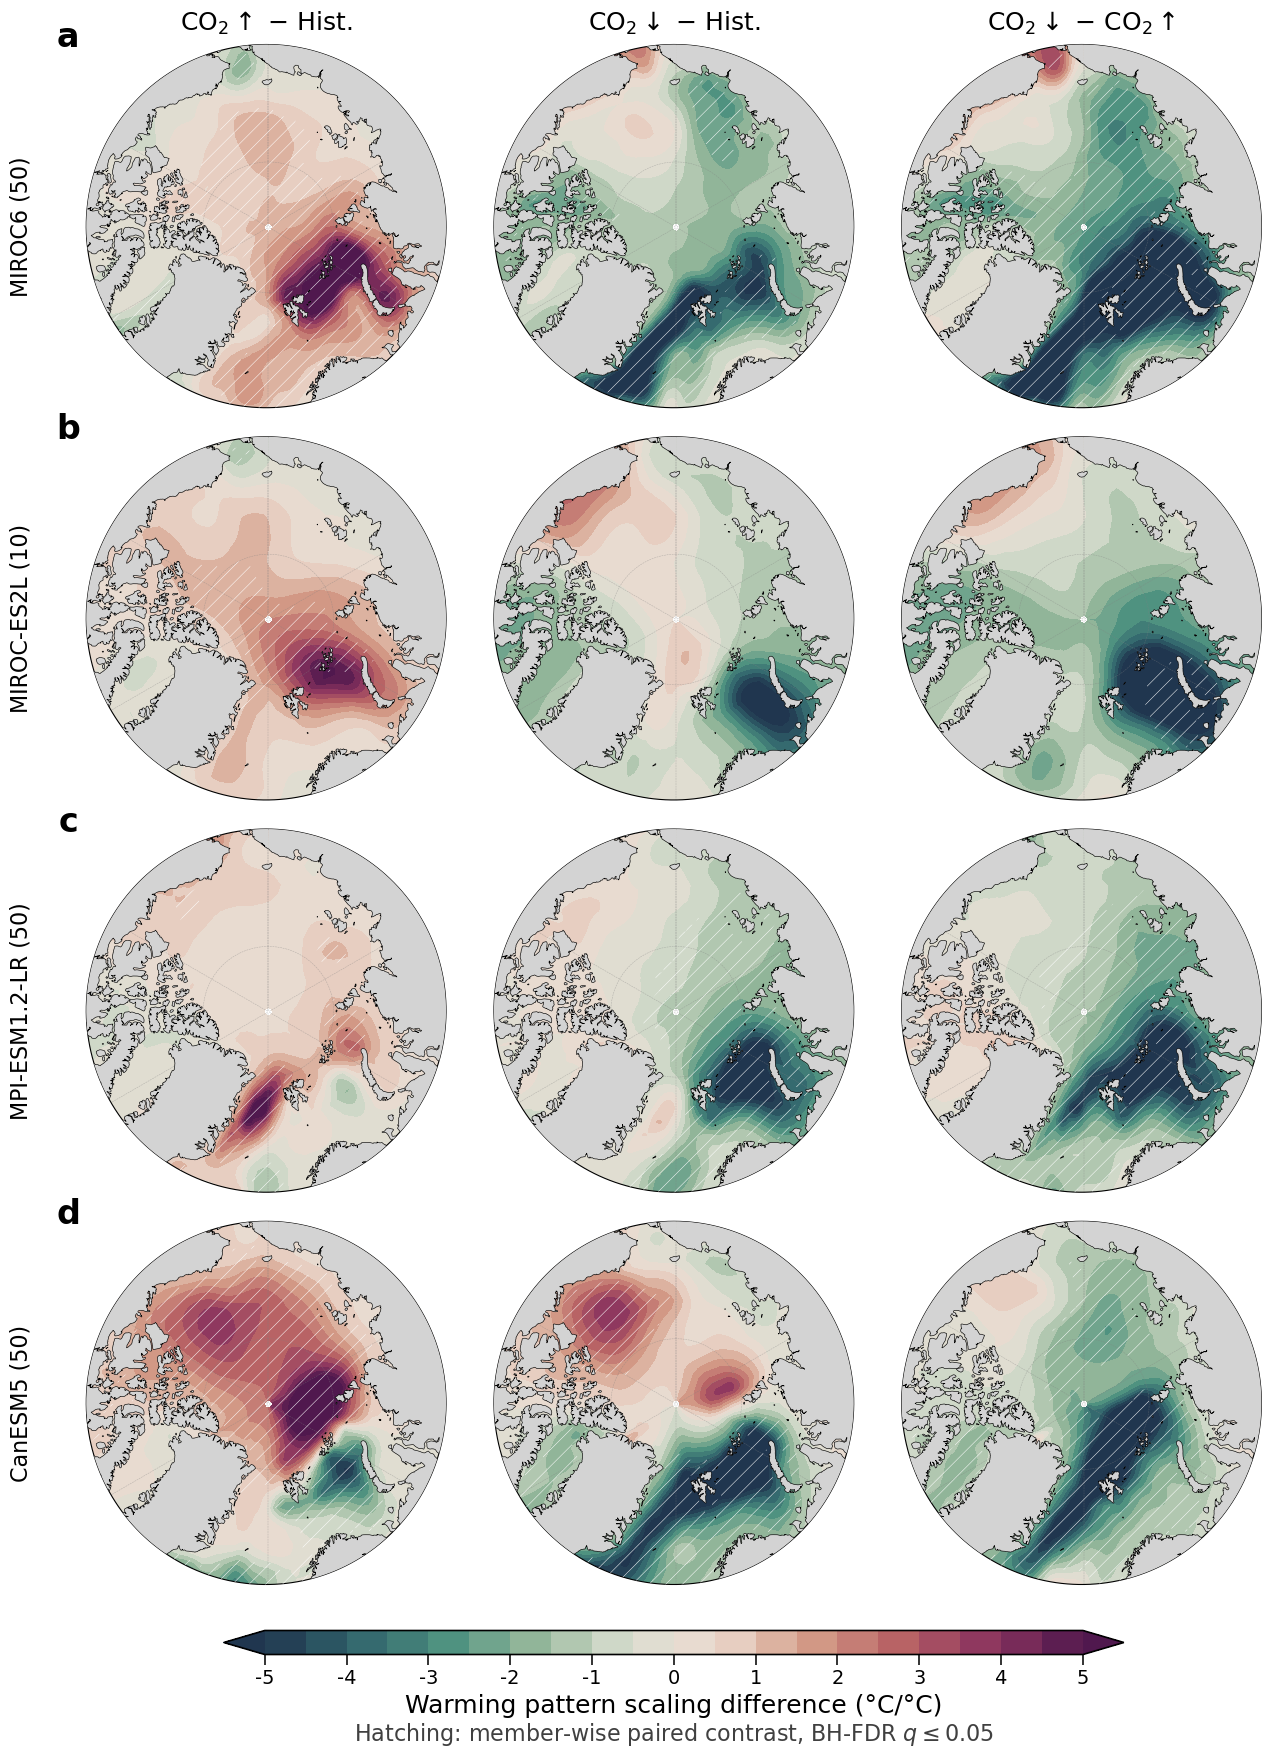

Loaded MIROC ssp126 MT_vs_Present: beta=(180, 360), FDR-significant ocean cells=4964
Loaded MIROC ssp126 LT_vs_Present: beta=(180, 360), FDR-significant ocean cells=4819
Loaded MIROC ssp126 LT_vs_MT: beta=(180, 360), FDR-significant ocean cells=5022
Loaded MIROC-ES2L ssp126 MT_vs_Present: beta=(180, 360), FDR-significant ocean cells=0
Loaded MIROC-ES2L ssp126 LT_vs_Present: beta=(180, 360), FDR-significant ocean cells=0
Loaded MIROC-ES2L ssp126 LT_vs_MT: beta=(180, 360), FDR-significant ocean cells=0
Loaded MPI-ESM-LR ssp126 MT_vs_Present: beta=(180, 360), FDR-significant ocean cells=482
Loaded MPI-ESM-LR ssp126 LT_vs_Present: beta=(180, 360), FDR-significant ocean cells=1441
Loaded MPI-ESM-LR ssp126 LT_vs_MT: beta=(180, 360), FDR-significant ocean cells=1790
Loaded CanESM5 ssp126 MT_vs_Present: beta=(180, 360), FDR-significant ocean cells=5325
Loaded CanESM5 ssp126 LT_vs_Present: beta=(180, 360), FDR-significant ocean cells=3180
Loaded CanESM5 ssp126 LT_vs_MT: beta=(180, 360), FDR-sig

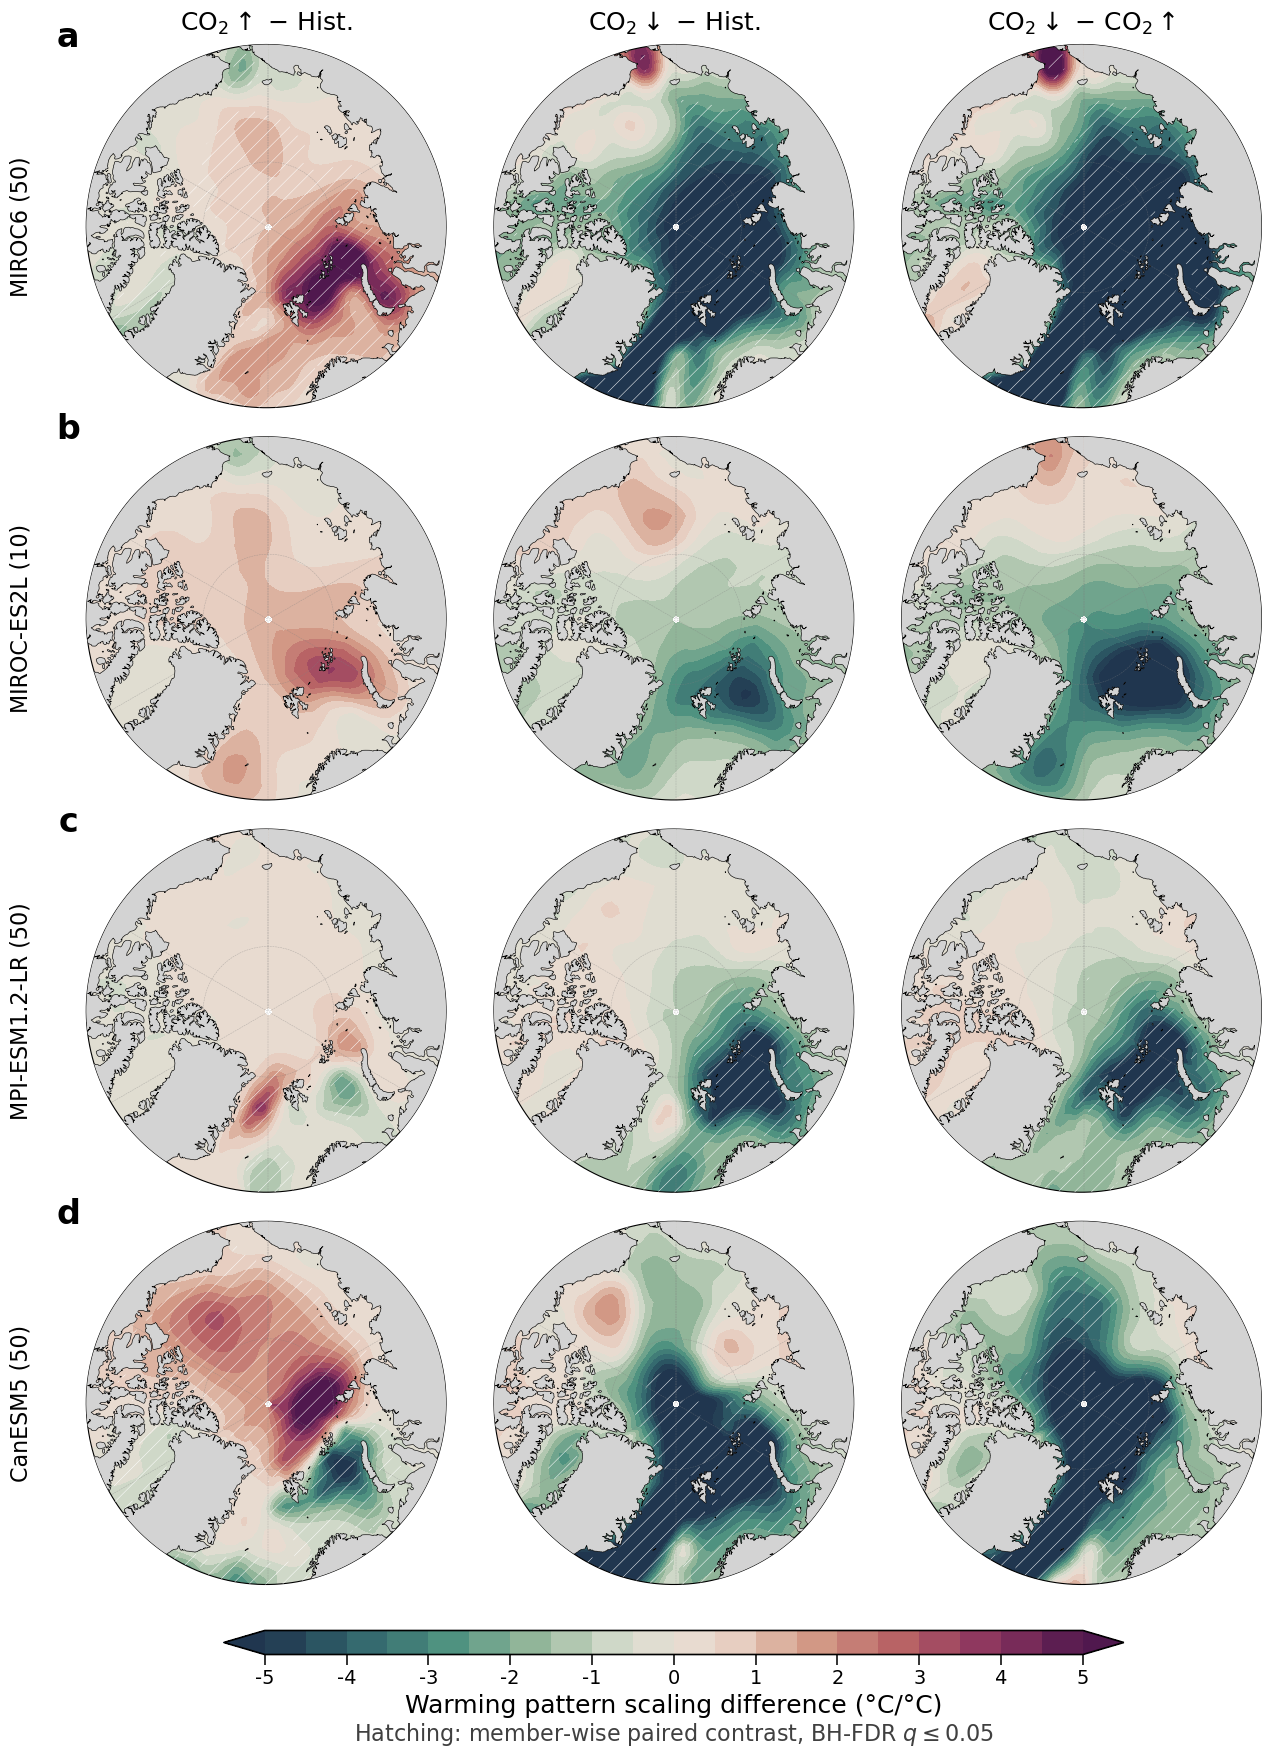

In [38]:
make_4le_figure_for_scenario("ssp119")
make_4le_figure_for_scenario("ssp126")